In [1]:
# ============================================================
# MEDINSIGHT AI
# Agentic Medical Report Analysis & RAG System
#
# Architecture:
#
# PDF / Image
#      ↓
# Document Extraction / OCR
#      ↓
# Structured Lab Extraction
#      ↓
# Deterministic Validation
#      ↓
# Pattern Analysis Agent
#      ↓
# RAG Retrieval
#      ↓
# Explanation Agent
#      ↓
# Deterministic Safety Gate
#      ↓
# LLM Safety Review
#      ↓
#      ├── PASS → Finalize
#      └── FAIL → Regenerate → Safety Gate
#
# Orchestrated using LangGraph
# ============================================================

print("MedInsight AI")
print("Agentic Medical Report Analysis & RAG System")

MedInsight AI
Agentic Medical Report Analysis & RAG System


In [2]:
# ============================================================
# INSTALL DEPENDENCIES
# ============================================================

!pip install -q \
    numpy==2.2.6 \
    scipy==1.15.3 \
    scikit-learn==1.6.1 \
    pandas==2.3.3 \
    pillow==11.3.0 \
    "pydantic<2.13" \
    transformers==4.56.2 \
    sentence-transformers==5.1.1 \
    accelerate \
    faiss-cpu \
    pymupdf \
    pytesseract \
    bitsandbytes \
    langgraph \
    langchain

In [3]:
# ============================================================
# TESSERACT OCR
# ============================================================

!apt-get update -qq
!apt-get install -y -qq tesseract-ocr

print("Tesseract installed.")

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
Tesseract installed.


In [4]:
# ============================================================
# IMPORTS
# ============================================================

import os
import re
import json
import math
import warnings
from pathlib import Path
from typing import TypedDict, Any, List, Dict, Optional

import numpy as np
import pandas as pd

import torch

import pymupdf
import pytesseract

from PIL import Image

from pydantic import BaseModel, Field

from transformers import AutoTokenizer, AutoModelForCausalLM

from sentence_transformers import SentenceTransformer

import faiss

from langgraph.graph import StateGraph, START, END

warnings.filterwarnings("ignore")

print("Imports successful.")

Imports successful.


/usr/local/lib/python3.12/dist-packages/langgraph/checkpoint/base/__init__.py:18: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


In [5]:
import numpy as np
import scipy
import sklearn
import pandas as pd

print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("scikit-learn:", sklearn.__version__)
print("Pandas:", pd.__version__)

from scipy.sparse import csr_matrix
from sklearn.metrics import roc_curve

print("\nScientific stack OK!")

NumPy: 2.2.6
SciPy: 1.15.3
scikit-learn: 1.6.1
Pandas: 2.3.3

Scientific stack OK!


In [6]:
import torch
import transformers
import sentence_transformers
import faiss
import pymupdf
import pytesseract
import langgraph
import langchain

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Transformers:", transformers.__version__)
print("Sentence Transformers:", sentence_transformers.__version__)
print("FAISS: OK")
print("PyMuPDF: OK")
print("Tesseract: OK")
print("LangGraph: OK")
print("LangChain: OK")

PyTorch: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4
Transformers: 4.56.2
Sentence Transformers: 5.1.1
FAISS: OK
PyMuPDF: OK
Tesseract: OK
LangGraph: OK
LangChain: OK


In [7]:
# ============================================================
# GPU CHECK
# ============================================================

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Using device:", device)

PyTorch version: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4
VRAM: 14.56 GB
Using device: cuda


In [8]:
# ============================================================
# CONFIGURATION
# ============================================================

MODEL_ID = "Qwen/Qwen2.5-3B-Instruct"

EMBEDDING_MODEL_ID = "sentence-transformers/all-MiniLM-L6-v2"

OUTPUT_DIR = Path("/kaggle/working/medinsight_output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

REPORT_PATH = None

print("LLM:", MODEL_ID)
print("Embedding model:", EMBEDDING_MODEL_ID)
print("Output directory:", OUTPUT_DIR)

LLM: Qwen/Qwen2.5-3B-Instruct
Embedding model: sentence-transformers/all-MiniLM-L6-v2
Output directory: /kaggle/working/medinsight_output


In [9]:
# ============================================================
# SYNTHETIC MEDICAL REPORT
# ============================================================

SAMPLE_REPORT = """
PATIENT LABORATORY REPORT

Patient: Synthetic Example
Age: 30 years
Sex: Female
Report Date: 2026-08-20

COMPLETE BLOOD COUNT

Hemoglobin             10.2 g/dL       Reference: 12.0 - 15.5
WBC Count              12,500 /uL      Reference: 4,000 - 11,000
Platelet Count         310,000 /uL     Reference: 150,000 - 450,000
MCV                    74 fL           Reference: 80 - 100
MCH                    24 pg           Reference: 27 - 33

IRON STUDIES

Ferritin               9 ng/mL         Reference: 15 - 150
Serum Iron             35 ug/dL        Reference: 50 - 170
TIBC                   420 ug/dL       Reference: 250 - 450

METABOLIC PANEL

Glucose (fasting)      96 mg/dL        Reference: 70 - 99
Creatinine             0.9 mg/dL       Reference: 0.6 - 1.1
"""

print(SAMPLE_REPORT)


PATIENT LABORATORY REPORT

Patient: Synthetic Example
Age: 30 years
Sex: Female
Report Date: 2026-08-20

COMPLETE BLOOD COUNT

Hemoglobin             10.2 g/dL       Reference: 12.0 - 15.5
WBC Count              12,500 /uL      Reference: 4,000 - 11,000
Platelet Count         310,000 /uL     Reference: 150,000 - 450,000
MCV                    74 fL           Reference: 80 - 100
MCH                    24 pg           Reference: 27 - 33

IRON STUDIES

Ferritin               9 ng/mL         Reference: 15 - 150
Serum Iron             35 ug/dL        Reference: 50 - 170
TIBC                   420 ug/dL       Reference: 250 - 450

METABOLIC PANEL

Glucose (fasting)      96 mg/dL        Reference: 70 - 99
Creatinine             0.9 mg/dL       Reference: 0.6 - 1.1



In [11]:
# ============================================================
# DOCUMENT EXTRACTION
# ============================================================

def ocr_image(image):
    return pytesseract.image_to_string(
        image.convert("RGB")
    )


def extract_pdf(path):
    doc = pymupdf.open(path)

    pages = []

    for i, page in enumerate(doc):

        text = page.get_text("text").strip()

        # If PDF contains little/no text, use OCR
        if len(text) < 50:

            pix = page.get_pixmap(
                matrix=pymupdf.Matrix(2, 2),
                alpha=False
            )

            img = Image.frombytes(
                "RGB",
                [pix.width, pix.height],
                pix.samples
            )

            text = ocr_image(img)

        pages.append(
            f"--- PAGE {i + 1} ---\n{text}"
        )

    doc.close()

    return "\n\n".join(pages)


def extract_file(path):

    ext = Path(path).suffix.lower()

    if ext == ".pdf":
        return extract_pdf(path)

    if ext in [
        ".png",
        ".jpg",
        ".jpeg",
        ".webp",
        ".bmp",
        ".tiff",
        ".tif"
    ]:
        return ocr_image(Image.open(path))

    if ext in [".txt", ".md"]:
        return Path(path).read_text(
            encoding="utf-8",
            errors="ignore"
        )

    raise ValueError(
        f"Unsupported file type: {ext}"
    )


print("Document extraction functions ready.")

Document extraction functions ready.


In [12]:
# ============================================================
# PYDANTIC STRUCTURED SCHEMAS
# ============================================================

class PatientInfo(BaseModel):

    age: Optional[float] = None
    sex: Optional[str] = None


class LaboratoryResult(BaseModel):

    Test: str
    Value: float
    Unit: str
    Reference_Low: float = Field(alias="Reference Low")
    Reference_High: float = Field(alias="Reference High")

    class Config:
        populate_by_name = True


class StructuredReport(BaseModel):

    patient: PatientInfo

    report_date: Optional[str] = None

    laboratory_results: List[LaboratoryResult]


print("Pydantic schemas ready.")

Pydantic schemas ready.


In [13]:
# ============================================================
# LOAD QWEN
# ============================================================

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    dtype=torch.float16 if device == "cuda" else torch.float32,
    device_map="auto" if device == "cuda" else None
)

print("Qwen model loaded.")

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

...

model-00002-of-00002.safetensors:   0%|          | 0.00/2.20G [00:00<?, ?B/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/3.97G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen model loaded.


In [14]:
# ============================================================
# LOCAL QWEN GENERATION
# ============================================================

def call_local_llm(
    system_prompt: str,
    user_prompt: str,
    max_new_tokens: int = 1000
) -> str:

    messages = [
        {
            "role": "system",
            "content": system_prompt
        },
        {
            "role": "user",
            "content": user_prompt
        }
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(model.device)
        for key, value in inputs.items()
    }

    with torch.no_grad():

        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    generated_tokens = outputs[
        0,
        inputs["input_ids"].shape[1]:
    ]

    response = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )

    return response.strip()


print("LLM helper ready.")

LLM helper ready.


In [15]:
# ============================================================
# ROBUST JSON PARSER
# ============================================================

def clean_json_text(raw: str) -> str:

    text = raw.strip()

    text = re.sub(
        r"^```json\s*",
        "",
        text,
        flags=re.IGNORECASE
    )

    text = re.sub(
        r"^```\s*",
        "",
        text
    )

    text = re.sub(
        r"\s*```$",
        "",
        text
    )

    start = text.find("{")
    end = text.rfind("}")

    if start >= 0 and end > start:
        text = text[start:end + 1]

    return text.strip()


def try_json_repair(text: str) -> str:

    text = re.sub(
        r'(")\s*\n(\s*")',
        r'\1,\n\2',
        text
    )

    text = re.sub(
        r'}\s*\n(\s*{)',
        r'},\n\1',
        text
    )

    return text


def call_local_llm_json(
    system_prompt: str,
    user_prompt: str,
    max_new_tokens: int = 1200,
    max_retries: int = 2
):

    last_raw = None

    for attempt in range(max_retries + 1):

        if attempt == 0:

            current_system_prompt = system_prompt

        else:

            current_system_prompt = system_prompt + """

IMPORTANT JSON REQUIREMENTS:

Return ONE JSON object only.

Do NOT use Markdown.

Do NOT use ```json.

Do NOT add explanations outside JSON.

Use double quotes for strings.

Every object field must be separated by commas.

Every array item must be separated by commas.

Before responding, verify that the JSON is valid.
"""

        raw = call_local_llm(
            current_system_prompt,
            user_prompt,
            max_new_tokens
        )

        last_raw = raw

        cleaned = clean_json_text(raw)

        try:

            return json.loads(cleaned)

        except json.JSONDecodeError:
            pass

        repaired = try_json_repair(cleaned)

        try:

            result = json.loads(repaired)

            print(
                f"JSON repaired on attempt {attempt + 1}"
            )

            return result

        except json.JSONDecodeError:

            if attempt < max_retries:

                print(
                    f"JSON parsing failed. "
                    f"Retrying ({attempt + 1}/{max_retries})..."
                )

    print("=" * 80)
    print("INVALID JSON FROM MODEL")
    print("=" * 80)
    print(last_raw)
    print("=" * 80)

    raise ValueError(
        "Local LLM did not return valid JSON."
    )


print("JSON helper ready.")

JSON helper ready.


In [16]:
# ============================================================
# STRUCTURED REPORT EXTRACTION
# ============================================================

STRUCTURED_EXTRACTION_PROMPT = """

You are a laboratory report extraction agent.

Extract ONLY information explicitly present
in the supplied laboratory report.

Do not diagnose the patient.

Do not infer medical conditions.

Return ONLY valid JSON.

Required structure:

{
    "patient": {
        "age": number or null,
        "sex": string or null
    },

    "report_date": string or null,

    "laboratory_results": [
        {
            "Test": string,
            "Value": number,
            "Unit": string,
            "Reference Low": number,
            "Reference High": number
        }
    ]
}

Important:

- Preserve laboratory values exactly.
- Do not change units.
- Do not invent missing values.
- Do not add tests that are not present.
"""


def extract_structured_report(
    raw_text: str
):

    result = call_local_llm_json(
        system_prompt=STRUCTURED_EXTRACTION_PROMPT,
        user_prompt=f"""
LABORATORY REPORT
=================

{raw_text}

Extract the structured laboratory information.
""",
        max_new_tokens=1800
    )

    return result


print("Structured extraction function ready.")

Structured extraction function ready.


In [17]:
# ============================================================
# TEST STRUCTURED EXTRACTION
# ============================================================

extraction = extract_structured_report(
    SAMPLE_REPORT
)

print(
    json.dumps(
        extraction,
        indent=2,
        ensure_ascii=False
    )
)

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


{
  "patient": {
    "age": 30,
    "sex": "Female"
  },
  "report_date": "2026-08-20",
  "laboratory_results": [
    {
      "Test": "Hemoglobin",
      "Value": 10.2,
      "Unit": "g/dL",
      "Reference Low": 12.0,
      "Reference High": 15.5
    },
    {
      "Test": "WBC Count",
      "Value": 12500,
      "Unit": "/uL",
      "Reference Low": 4000,
      "Reference High": 11000
    },
    {
      "Test": "Platelet Count",
      "Value": 310000,
      "Unit": "/uL",
      "Reference Low": 150000,
      "Reference High": 450000
    },
    {
      "Test": "MCV",
      "Value": 74,
      "Unit": "fL",
      "Reference Low": 80,
      "Reference High": 100
    },
    {
      "Test": "MCH",
      "Value": 24,
      "Unit": "pg",
      "Reference Low": 27,
      "Reference High": 33
    },
    {
      "Test": "Ferritin",
      "Value": 9,
      "Unit": "ng/mL",
      "Reference Low": 15,
      "Reference High": 150
    },
    {
      "Test": "Serum Iron",
      "Value": 35,
      "U

In [18]:
# ============================================================
# STRUCTURED DATAFRAME
# ============================================================

patient_data = extraction["patient"]

laboratory_results = extraction[
    "laboratory_results"
]

lab_df = pd.DataFrame(
    laboratory_results
)

lab_df

,Test,Value,Unit,Reference Low,Reference High
0,Hemoglobin,10.2,g/dL,12.0,15.5
1,WBC Count,12500.0,/uL,4000.0,11000.0
2,Platelet Count,310000.0,/uL,150000.0,450000.0
3,MCV,74.0,fL,80.0,100.0
4,MCH,24.0,pg,27.0,33.0
5,Ferritin,9.0,ng/mL,15.0,150.0
6,Serum Iron,35.0,ug/dL,50.0,170.0
7,TIBC,420.0,ug/dL,250.0,450.0
8,Glucose (fasting),96.0,mg/dL,70.0,99.0
9,Creatinine,0.9,mg/dL,0.6,1.1


In [20]:
# ============================================================
# DETERMINISTIC LAB VALIDATION
# ============================================================

def validate_lab_results(
    results: List[Dict[str, Any]]
):

    validated = []
    errors = []

    for result in results:

        try:

            value = float(
                result["Value"]
            )

            low = float(
                result["Reference Low"]
            )

            high = float(
                result["Reference High"]
            )

            if value < low:

                status = "LOW"

            elif value > high:

                status = "HIGH"

            else:

                status = "NORMAL"

            validated_result = dict(result)

            validated_result["Status"] = status

            validated.append(
                validated_result
            )

        except Exception as e:

            errors.append(
                f"Validation error for "
                f"{result.get('Test', 'unknown')}: {e}"
            )

    return validated, errors


validated_results, validation_errors = validate_lab_results(
    laboratory_results
)

validated_df = pd.DataFrame(
    validated_results
)

validated_df

,Test,Value,Unit,Reference Low,Reference High,Status
0,Hemoglobin,10.2,g/dL,12.0,15.5,LOW
1,WBC Count,12500.0,/uL,4000.0,11000.0,HIGH
2,Platelet Count,310000.0,/uL,150000.0,450000.0,NORMAL
3,MCV,74.0,fL,80.0,100.0,LOW
4,MCH,24.0,pg,27.0,33.0,LOW
5,Ferritin,9.0,ng/mL,15.0,150.0,LOW
6,Serum Iron,35.0,ug/dL,50.0,170.0,LOW
7,TIBC,420.0,ug/dL,250.0,450.0,NORMAL
8,Glucose (fasting),96.0,mg/dL,70.0,99.0,NORMAL
9,Creatinine,0.9,mg/dL,0.6,1.1,NORMAL


In [21]:
# ============================================================
# MEDICAL KNOWLEDGE BASE
# ============================================================

MEDICAL_KNOWLEDGE = [

    {
        "topic": "Iron-related laboratory pattern",
        "evidence": (
            "A laboratory pattern involving low ferritin, "
            "low serum iron, relatively increased or high TIBC, "
            "and smaller red blood cell indices such as low MCV "
            "and low MCH can be associated with an iron-related "
            "laboratory pattern. Interpretation should consider "
            "the laboratory reference ranges and clinical context."
        )
    },

    {
        "topic": "MCV",
        "evidence": (
            "Mean corpuscular volume (MCV) describes the average "
            "size of red blood cells. A low MCV indicates "
            "smaller-than-average red blood cells and is commonly "
            "described as a microcytic laboratory pattern."
        )
    },

    {
        "topic": "MCH",
        "evidence": (
            "Mean corpuscular hemoglobin (MCH) describes the "
            "average amount of hemoglobin contained in a red "
            "blood cell. A low MCH can occur with hypochromic "
            "red blood cells and should be interpreted together "
            "with other laboratory findings."
        )
    },

    {
        "topic": "Hemoglobin",
        "evidence": (
            "Hemoglobin is the oxygen-carrying protein in red "
            "blood cells. A value below the laboratory reference "
            "range represents a low hemoglobin laboratory finding."
        )
    },

    {
        "topic": "WBC Count",
        "evidence": (
            "White blood cell count measures the number of "
            "white blood cells in a given volume of blood. "
            "Values above the laboratory reference range "
            "represent an elevated WBC laboratory finding."
        )
    },

    {
        "topic": "Creatinine",
        "evidence": (
            "Creatinine is a laboratory measurement commonly "
            "used as part of assessment of kidney function. "
            "Interpretation should consider the laboratory "
            "reference range and clinical context."
        )
    },

    {
        "topic": "Glucose",
        "evidence": (
            "Fasting glucose measures blood glucose after "
            "a period without food. Interpretation depends "
            "on the laboratory reference range and clinical context."
        )
    }
]

knowledge_df = pd.DataFrame(
    MEDICAL_KNOWLEDGE
)

knowledge_df

,topic,evidence
0,Iron-related laboratory pattern,"A laboratory pattern involving low ferritin, l..."
1,MCV,Mean corpuscular volume (MCV) describes the av...
2,MCH,Mean corpuscular hemoglobin (MCH) describes th...
3,Hemoglobin,Hemoglobin is the oxygen-carrying protein in r...
4,WBC Count,White blood cell count measures the number of ...
5,Creatinine,Creatinine is a laboratory measurement commonl...
6,Glucose,Fasting glucose measures blood glucose after a...


In [22]:
# ============================================================
# SENTENCE TRANSFORMER
# ============================================================

embedding_model = SentenceTransformer(
    EMBEDDING_MODEL_ID,
    device=device
)

print("Embedding model loaded.")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding model loaded.


In [23]:
# ============================================================
# BUILD FAISS INDEX
# ============================================================

knowledge_texts = [
    item["evidence"]
    for item in MEDICAL_KNOWLEDGE
]

embeddings = embedding_model.encode(
    knowledge_texts,
    convert_to_numpy=True,
    normalize_embeddings=True
)

embedding_dimension = embeddings.shape[1]

faiss_index = faiss.IndexFlatIP(
    embedding_dimension
)

faiss_index.add(
    embeddings.astype(np.float32)
)

print("FAISS index created.")
print("Documents:", faiss_index.ntotal)
print("Embedding dimension:", embedding_dimension)

FAISS index created.
Documents: 7
Embedding dimension: 384


In [24]:
# ============================================================
# RAG RETRIEVAL
# ============================================================

def retrieve_medical_evidence(
    query: str,
    top_k: int = 3
):

    query_embedding = embedding_model.encode(
        [query],
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    scores, indices = faiss_index.search(
        query_embedding.astype(np.float32),
        top_k
    )

    results = []

    for score, index in zip(
        scores[0],
        indices[0]
    ):

        if index < 0:
            continue

        results.append({
            "topic": MEDICAL_KNOWLEDGE[index]["topic"],
            "score": float(score),
            "evidence": MEDICAL_KNOWLEDGE[index]["evidence"]
        })

    return results


print("RAG retrieval function ready.")

RAG retrieval function ready.


In [25]:
# ============================================================
# TEST RAG
# ============================================================

test_evidence = retrieve_medical_evidence(
    "low hemoglobin low MCV low ferritin low serum iron"
)

print(
    json.dumps(
        test_evidence,
        indent=2
    )
)

[
  {
    "topic": "Iron-related laboratory pattern",
    "score": 0.7654130458831787,
    "evidence": "A laboratory pattern involving low ferritin, low serum iron, relatively increased or high TIBC, and smaller red blood cell indices such as low MCV and low MCH can be associated with an iron-related laboratory pattern. Interpretation should consider the laboratory reference ranges and clinical context."
  },
  {
    "topic": "Hemoglobin",
    "score": 0.49264854192733765,
    "evidence": "Hemoglobin is the oxygen-carrying protein in red blood cells. A value below the laboratory reference range represents a low hemoglobin laboratory finding."
  },
  {
    "topic": "MCH",
    "score": 0.48046058416366577,
    "evidence": "Mean corpuscular hemoglobin (MCH) describes the average amount of hemoglobin contained in a red blood cell. A low MCH can occur with hypochromic red blood cells and should be interpreted together with other laboratory findings."
  }
]


In [26]:
# ============================================================
# PATTERN ANALYSIS AGENT
# ============================================================

PATTERN_SYSTEM_PROMPT = """

You are a Laboratory Pattern Analysis Agent.

Your task is to identify patterns in validated laboratory
results.

IMPORTANT SAFETY RULES:

Do NOT diagnose.

Do NOT say that the patient has a disease or condition.

Do NOT use definitive diagnosis terminology.

Do NOT recommend treatment.

Do NOT recommend medication.

Use laboratory-pattern terminology only.

Examples of acceptable terminology:

- microcytic laboratory pattern
- iron-related laboratory pattern
- elevated WBC pattern
- normal glucose laboratory finding

Avoid:

- anemia
- iron deficiency
- infection
- disease
- diagnosis
- treatment

Return ONLY valid JSON.

Structure:

{
    "patterns": [
        {
            "name": string,
            "description": string,
            "supporting_tests": [string],
            "confidence": "low" | "moderate" | "high"
        }
    ]
}
"""


def pattern_analysis_agent(
    validated_results
):

    prompt = f"""
VALIDATED LABORATORY RESULTS
============================

{json.dumps(
    validated_results,
    indent=2
)}

Identify laboratory patterns.

Remember:

Use only laboratory-pattern terminology.
Do not diagnose.
"""

    return call_local_llm_json(
        PATTERN_SYSTEM_PROMPT,
        prompt,
        max_new_tokens=1400
    )


pattern_json = pattern_analysis_agent(
    validated_results
)

print(
    json.dumps(
        pattern_json,
        indent=2
    )
)

{
  "patterns": [
    {
      "name": "microcytic laboratory pattern",
      "description": "characterized by low mean corpuscular volume (MCV) and low mean corpuscular hemoglobin (MCH), indicating iron deficiency.",
      "supporting_tests": [
        "MCV",
        "MCH"
      ],
      "confidence": "high"
    },
    {
      "name": "iron-related laboratory pattern",
      "description": "evidenced by low hemoglobin, ferritin, and serum iron levels, consistent with iron deficiency.",
      "supporting_tests": [
        "Hemoglobin",
        "Ferritin",
        "Serum Iron"
      ],
      "confidence": "high"
    },
    {
      "name": "elevated WBC pattern",
      "description": "indicated by high white blood cell count, possibly indicative of inflammation or infection.",
      "supporting_tests": [
        "WBC Count"
      ],
      "confidence": "moderate"
    }
  ]
}


In [27]:
# ============================================================
# EXPLANATION AGENT
# ============================================================

EXPLANATION_SYSTEM_PROMPT = """

You are a Medical Laboratory Explanation Agent.

Explain laboratory findings in understandable language.

Use ONLY:

1. Validated laboratory results.
2. Detected laboratory patterns.
3. Retrieved evidence.

IMPORTANT SAFETY RULES:

Do NOT diagnose.

Do NOT state that the patient has a disease.

Do NOT prescribe medication.

Do NOT recommend treatment.

Do NOT recommend dosage.

Do NOT invent laboratory values.

Do NOT introduce medical claims that are unsupported
by the retrieved evidence.

Distinguish clearly between:

1. Observed laboratory finding
2. Laboratory pattern
3. Possible association
4. Limitations

Use cautious wording such as:

"may be consistent with a laboratory pattern"

"can be associated with"

"should be interpreted in context"

Avoid definitive statements.

Use "iron-related laboratory pattern" rather than
"iron deficiency".

Use "microcytic laboratory pattern" rather than
"microcytic anemia".

Return ONLY valid JSON.

Structure:

{
    "summary": string,

    "key_findings": [
        {
            "finding": string,
            "explanation": string,
            "supporting_tests": [string]
        }
    ],

    "limitations": [string]
}
"""


def explanation_agent(
    validated_results,
    patterns,
    retrieved_evidence
):

    prompt = f"""

VALIDATED LABORATORY RESULTS
============================

{json.dumps(
    validated_results,
    indent=2
)}


PATTERN ANALYSIS
================

{json.dumps(
    patterns,
    indent=2
)}


RETRIEVED MEDICAL EVIDENCE
==========================

{json.dumps(
    retrieved_evidence,
    indent=2
)}


Explain the report using ONLY the information above.

Do not diagnose.
Do not recommend treatment.
"""

    return call_local_llm_json(
        EXPLANATION_SYSTEM_PROMPT,
        prompt,
        max_new_tokens=1800
    )


# Build query for RAG
pattern_names = [
    p["name"]
    for p in pattern_json.get(
        "patterns",
        []
    )
]

rag_query = " ".join(pattern_names)

retrieved_evidence = retrieve_medical_evidence(
    rag_query
)

explanation_json = explanation_agent(
    validated_results,
    pattern_json,
    retrieved_evidence
)

print(
    json.dumps(
        explanation_json,
        indent=2
    )
)

{
  "summary": "The laboratory findings indicate a microcytic laboratory pattern characterized by low hemoglobin, ferritin, and serum iron levels, which are consistent with iron deficiency. Additionally, there is an elevated white blood cell count, which may suggest inflammation or infection. These findings should be interpreted in the context of the patient's overall health and any relevant clinical symptoms or history.",
  "key_findings": [
    {
      "finding": "Hemoglobin 10.2 g/dL (LOW)",
      "explanation": "This value is below the normal range and may be consistent with a microcytic laboratory pattern.",
      "supporting_tests": [
        "MCV",
        "MCH",
        "Ferritin",
        "Serum Iron"
      ]
    },
    {
      "finding": "WBC Count 12,500 /uL (HIGH)",
      "explanation": "This value is above the normal range and can be associated with an elevated WBC pattern.",
      "supporting_tests": [
        "WBC Count"
      ]
    },
    {
      "finding": "MCV 74 fL (

In [28]:
# ============================================================
# DETERMINISTIC SAFETY CHECKS
# ============================================================

FORBIDDEN_PATTERNS = [

    # Definitive diagnosis language
    r"\bthe patient has\b",
    r"\bdiagnosed with\b",
    r"\bdiagnosis is\b",
    r"\bthis confirms\b",
    r"\bthis proves\b",
    r"\bproves that\b",

    # Treatment
    r"\btake\s+(?:iron|medication|medicine|supplements?)\b",
    r"\bstart\s+(?:iron|medication|medicine|supplements?)\b",
    r"\bstop\s+(?:iron|medication|medicine|supplements?)\b",
    r"\brecommend(?:ed|s)?\s+(?:treatment|medication|supplements?)\b",
    r"\bprescribe\b",
    r"\bdosage\b",

    # Explicit disease/condition statements
    r"\bhas iron deficiency\b",
    r"\bhas iron-deficiency\b",
    r"\bhas anemia\b",
    r"\bhas microcytic anemia\b",
    r"\bhas inflammation\b"
]


def deterministic_safety_check(
    explanation
):

    text = json.dumps(
        explanation,
        ensure_ascii=False
    )

    issues = []

    for pattern in FORBIDDEN_PATTERNS:

        matches = re.findall(
            pattern,
            text,
            flags=re.IGNORECASE
        )

        if matches:

            issues.append({
                "issue_type": "forbidden_medical_language",
                "pattern": pattern,
                "matches": matches
            })

    return {
        "approved": len(issues) == 0,
        "issues": issues
    }


print("Deterministic safety checker ready.")

Deterministic safety checker ready.


In [29]:
# ============================================================
# GROUNDING SAFETY CHECK
# ============================================================

def get_validated_test_names(
    validated_results
):

    return {
        str(result["Test"])
        .strip()
        .lower()

        for result in validated_results
    }


def grounding_safety_check(
    explanation,
    validated_results
):

    valid_tests = get_validated_test_names(
        validated_results
    )

    issues = []

    for finding in explanation.get(
        "key_findings",
        []
    ):

        for test in finding.get(
            "supporting_tests",
            []
        ):

            if test.lower().strip() not in valid_tests:

                issues.append({
                    "issue_type": "unknown_supporting_test",
                    "test": test
                })

    return {
        "approved": len(issues) == 0,
        "issues": issues
    }


print("Grounding checker ready.")

Grounding checker ready.


In [30]:
# ============================================================
# COMBINED DETERMINISTIC SAFETY
# ============================================================

def run_deterministic_safety(
    explanation,
    validated_results
):

    language_check = deterministic_safety_check(
        explanation
    )

    grounding_check = grounding_safety_check(
        explanation,
        validated_results
    )

    issues = (
        language_check["issues"]
        +
        grounding_check["issues"]
    )

    return {
        "approved": len(issues) == 0,
        "issues": issues
    }


deterministic_result = run_deterministic_safety(
    explanation_json,
    validated_results
)

print(
    json.dumps(
        deterministic_result,
        indent=2
    )
)

{
  "approved": true,
  "issues": []
}


In [31]:
# ============================================================
# LLM SAFETY REVIEW AGENT
# ============================================================

SAFETY_SYSTEM_PROMPT = """

You are a strict safety review agent for a laboratory
report explanation system.

Review the generated explanation.

Your task is ONLY to determine whether the explanation
contains:

1. Definitive diagnosis.
2. Treatment recommendation.
3. Medication recommendation.
4. Unsupported laboratory claims.
5. Unsupported medical claims.
6. Contradictions with validated laboratory results.

IMPORTANT:

Do NOT invent violations.

Only report an issue if the generated explanation
actually contains that problem.

Do NOT classify cautious language such as:

"may be consistent with"

"can be associated with"

"should be interpreted in context"

as a diagnosis.

Do NOT treat the statement:

"Laboratory findings alone do not establish a diagnosis."

as a safety violation.

Return ONLY valid JSON.

Structure:

{
    "approved": true or false,

    "issues": [
        {
            "issue_type": string,
            "finding": string
        }
    ]
}

If there are no real violations:

{
    "approved": true,
    "issues": []
}
"""


def safety_review_agent(
    explanation,
    validated_results,
    retrieved_evidence
):

    prompt = f"""

VALIDATED LABORATORY RESULTS
============================

{json.dumps(
    validated_results,
    indent=2
)}


RETRIEVED EVIDENCE
==================

{json.dumps(
    retrieved_evidence,
    indent=2
)}


GENERATED EXPLANATION
=====================

{json.dumps(
    explanation,
    indent=2
)}


Review this explanation.

Do not invent violations.
"""

    return call_local_llm_json(
        SAFETY_SYSTEM_PROMPT,
        prompt,
        max_new_tokens=1200
    )


safety_review = safety_review_agent(
    explanation_json,
    validated_results,
    retrieved_evidence
)

print(
    json.dumps(
        safety_review,
        indent=2
    )
)

{
  "approved": true,
  "issues": []
}


In [32]:
# ============================================================
# LANGGRAPH STATE
# ============================================================

class MedicalReportState(TypedDict, total=False):

    report_path: Optional[str]

    raw_text: str

    chunks: List[str]

    patient: Dict[str, Any]

    report_date: Optional[str]

    laboratory_results: List[Dict[str, Any]]

    validated_results: List[Dict[str, Any]]

    validation_errors: List[str]

    patterns: Dict[str, Any]

    retrieved_evidence: List[Dict[str, Any]]

    explanation: Dict[str, Any]

    deterministic_safety: Dict[str, Any]

    safety_review: Dict[str, Any]

    final_report: Dict[str, Any]

    safety_attempts: int

    errors: List[str]


print("LangGraph state defined.")

LangGraph state defined.


In [33]:
# ============================================================
# LANGGRAPH
# ============================================================

from langgraph.graph import (
    StateGraph,
    START,
    END
)

print("LangGraph imported successfully.")

LangGraph imported successfully.


In [34]:
# ============================================================
# NODE 1
# DOCUMENT EXTRACTION
# ============================================================

def extract_document_node(
    state: MedicalReportState
):

    print("\n" + "=" * 70)
    print("NODE: DOCUMENT EXTRACTION")
    print("=" * 70)

    report_path = state.get(
        "report_path"
    )

    try:

        if report_path:

            raw_text = extract_file(
                report_path
            )

        else:

            raw_text = SAMPLE_REPORT

        print(
            "Extracted characters:",
            len(raw_text)
        )

        return {
            "raw_text": raw_text,
            "errors": []
        }

    except Exception as e:

        print(
            "Extraction error:",
            str(e)
        )

        return {
            "raw_text": "",
            "errors": [
                f"Document extraction failed: {str(e)}"
            ]
        }

In [35]:
# ============================================================
# NODE 2
# DOCUMENT CHUNKING
# ============================================================

def chunk_document_node(
    state: MedicalReportState
):

    print("\n" + "=" * 70)
    print("NODE: DOCUMENT CHUNKING")
    print("=" * 70)

    text = state.get(
        "raw_text",
        ""
    )

    if not text:

        return {
            "chunks": []
        }

    chunk_size = 1000
    overlap = 150

    chunks = []

    start = 0

    while start < len(text):

        end = start + chunk_size

        chunk = text[start:end]

        if chunk.strip():

            chunks.append(
                chunk.strip()
            )

        start = end - overlap

    print(
        "Created chunks:",
        len(chunks)
    )

    return {
        "chunks": chunks
    }

In [36]:
# ============================================================
# NODE 3
# STRUCTURED LAB EXTRACTION
# ============================================================

def extract_lab_values_node(
    state: MedicalReportState
):

    print("\n" + "=" * 70)
    print("NODE: STRUCTURED LAB EXTRACTION")
    print("=" * 70)

    raw_text = state.get(
        "raw_text",
        ""
    )

    try:

        extraction = extract_structured_report(
            raw_text
        )

        patient = extraction.get(
            "patient",
            {}
        )

        laboratory_results = extraction.get(
            "laboratory_results",
            []
        )

        report_date = extraction.get(
            "report_date"
        )

        print(
            "Laboratory values extracted:",
            len(laboratory_results)
        )

        return {

            "patient": patient,

            "report_date": report_date,

            "laboratory_results":
                laboratory_results

        }

    except Exception as e:

        print(
            "Structured extraction error:",
            str(e)
        )

        return {

            "patient": {},

            "laboratory_results": [],

            "errors": [
                f"Structured extraction failed: {str(e)}"
            ]

        }

In [37]:
# ============================================================
# NODE 4
# DETERMINISTIC VALIDATION
# ============================================================

def validate_values_node(
    state: MedicalReportState
):

    print("\n" + "=" * 70)
    print("NODE: DETERMINISTIC VALIDATION")
    print("=" * 70)

    results = state.get(
        "laboratory_results",
        []
    )

    validated, errors = validate_lab_results(
        results
    )

    print(
        "Validated results:",
        len(validated)
    )

    print(
        "Validation errors:",
        len(errors)
    )

    return {

        "validated_results":
            validated,

        "validation_errors":
            errors

    }

In [38]:
# ============================================================
# NODE 5
# PATTERN ANALYSIS AGENT
# ============================================================

def pattern_analysis_node(
    state: MedicalReportState
):

    print("\n" + "=" * 70)
    print("NODE: PATTERN ANALYSIS AGENT")
    print("=" * 70)

    validated_results = state.get(
        "validated_results",
        []
    )

    try:

        patterns = pattern_analysis_agent(
            validated_results
        )

        print(
            json.dumps(
                patterns,
                indent=2
            )
        )

        return {
            "patterns": patterns
        }

    except Exception as e:

        print(
            "Pattern analysis error:",
            str(e)
        )

        return {

            "patterns": {
                "patterns": []
            },

            "errors": [
                f"Pattern analysis failed: {str(e)}"
            ]

        }

In [39]:
# ============================================================
# NODE 6
# RAG RETRIEVAL
# ============================================================

def retrieve_evidence_node(
    state: MedicalReportState
):

    print("\n" + "=" * 70)
    print("NODE: RAG RETRIEVAL")
    print("=" * 70)

    patterns = state.get(
        "patterns",
        {}
    )

    pattern_list = patterns.get(
        "patterns",
        []
    )

    pattern_names = [
        p.get("name", "")
        for p in pattern_list
    ]

    query = " ".join(
        pattern_names
    )

    # Add abnormal test names
    for result in state.get(
        "validated_results",
        []
    ):

        if result.get("Status") != "NORMAL":

            query += " " + result.get(
                "Test",
                ""
            )

    print(
        "RAG query:",
        query
    )

    evidence = retrieve_medical_evidence(
        query,
        top_k=3
    )

    print(
        "Retrieved documents:",
        len(evidence)
    )

    return {
        "retrieved_evidence": evidence
    }

In [40]:
# ============================================================
# NODE 7
# EXPLANATION AGENT
# ============================================================

def explanation_node(
    state: MedicalReportState
):

    print("\n" + "=" * 70)
    print("NODE: EXPLANATION AGENT")
    print("=" * 70)

    validated_results = state.get(
        "validated_results",
        []
    )

    patterns = state.get(
        "patterns",
        {}
    )

    evidence = state.get(
        "retrieved_evidence",
        []
    )

    try:

        explanation = explanation_agent(
            validated_results,
            patterns,
            evidence
        )

        print(
            json.dumps(
                explanation,
                indent=2
            )
        )

        return {
            "explanation": explanation
        }

    except Exception as e:

        print(
            "Explanation error:",
            str(e)
        )

        return {

            "explanation": {
                "summary":
                    "Automated explanation unavailable.",

                "key_findings": [],

                "limitations": [
                    "Explanation generation failed."
                ]
            },

            "errors": [
                f"Explanation generation failed: {str(e)}"
            ]

        }

In [41]:
# ============================================================
# NODE 8
# DETERMINISTIC SAFETY GATE
# ============================================================

def deterministic_safety_node(
    state: MedicalReportState
):

    print("\n" + "=" * 70)
    print("NODE: DETERMINISTIC SAFETY GATE")
    print("=" * 70)

    explanation = state.get(
        "explanation",
        {}
    )

    validated_results = state.get(
        "validated_results",
        []
    )

    result = run_deterministic_safety(
        explanation,
        validated_results
    )

    print(
        "Safety approved:",
        result["approved"]
    )

    if result["issues"]:

        print(
            json.dumps(
                result["issues"],
                indent=2
            )
        )

    return {
        "deterministic_safety": result
    }

In [42]:
# ============================================================
# NODE 9
# LLM SAFETY REVIEW
# ============================================================

def safety_review_node(
    state: MedicalReportState
):

    print("\n" + "=" * 70)
    print("NODE: LLM SAFETY REVIEW")
    print("=" * 70)

    explanation = state.get(
        "explanation",
        {}
    )

    validated_results = state.get(
        "validated_results",
        []
    )

    evidence = state.get(
        "retrieved_evidence",
        []
    )

    try:

        review = safety_review_agent(
            explanation,
            validated_results,
            evidence
        )

        print(
            json.dumps(
                review,
                indent=2
            )
        )

        return {
            "safety_review": review
        }

    except Exception as e:

        print(
            "Safety review error:",
            str(e)
        )

        # Fail closed
        return {

            "safety_review": {
                "approved": False,
                "issues": [
                    {
                        "issue_type":
                            "safety_review_failure",

                        "finding":
                            "Safety review failed."
                    }
                ]
            },

            "errors": [
                f"Safety review failed: {str(e)}"
            ]

        }

In [43]:
# ============================================================
# NODE 10
# REGENERATE EXPLANATION
# ============================================================

def regenerate_explanation_node(
    state: MedicalReportState
):

    print("\n" + "=" * 70)
    print("NODE: REGENERATE SAFE EXPLANATION")
    print("=" * 70)

    validated_results = state.get(
        "validated_results",
        []
    )

    patterns = state.get(
        "patterns",
        {}
    )

    evidence = state.get(
        "retrieved_evidence",
        []
    )

    deterministic = state.get(
        "deterministic_safety",
        {}
    )

    safety_review = state.get(
        "safety_review",
        {}
    )

    attempts = state.get(
        "safety_attempts",
        0
    )

    attempts += 1

    issues = (
        deterministic.get(
            "issues",
            []
        )
        +
        safety_review.get(
            "issues",
            []
        )
    )

    regeneration_prompt = """

The previous explanation failed a safety review.

Generate a new explanation.

IMPORTANT:

- Do not diagnose.
- Do not recommend treatment.
- Do not recommend medication.
- Do not give dosage.
- Do not make unsupported medical claims.
- Use laboratory-pattern terminology.
- Use only validated results and retrieved evidence.
- Keep uncertainty explicit.
"""

    issue_text = json.dumps(
        issues,
        indent=2
    )

    base_prompt = f"""

VALIDATED LABORATORY RESULTS
============================

{json.dumps(
    validated_results,
    indent=2
)}


PATTERNS
========

{json.dumps(
    patterns,
    indent=2
)}


RETRIEVED EVIDENCE
==================

{json.dumps(
    evidence,
    indent=2
)}


SAFETY ISSUES FROM PREVIOUS OUTPUT
==================================

{issue_text}


{regeneration_prompt}

Return ONLY valid JSON using:

{{
    "summary": "...",
    "key_findings": [],
    "limitations": []
}}
"""

    regenerated = call_local_llm_json(
        EXPLANATION_SYSTEM_PROMPT,
        base_prompt,
        max_new_tokens=1800
    )

    print(
        "Regeneration attempt:",
        attempts
    )

    return {

        "explanation":
            regenerated,

        "safety_attempts":
            attempts

    }

In [44]:
# ============================================================
# CONDITIONAL SAFETY ROUTER
# ============================================================

MAX_SAFETY_ATTEMPTS = 2


def safety_router(
    state: MedicalReportState
):

    deterministic = state.get(
        "deterministic_safety",
        {}
    )

    safety = state.get(
        "safety_review",
        {}
    )

    attempts = state.get(
        "safety_attempts",
        0
    )

    # Deterministic safety must ALWAYS pass.
    if not deterministic.get(
        "approved",
        False
    ):

        if attempts < MAX_SAFETY_ATTEMPTS:

            print(
                "ROUTER: Deterministic safety FAILED"
            )

            return "regenerate"

        print(
            "ROUTER: Maximum retries reached"
        )

        return "blocked"

    # Semantic safety
    if not safety.get(
        "approved",
        False
    ):

        if attempts < MAX_SAFETY_ATTEMPTS:

            print(
                "ROUTER: LLM safety FAILED"
            )

            return "regenerate"

        print(
            "ROUTER: Maximum retries reached"
        )

        return "blocked"

    print(
        "ROUTER: SAFETY PASSED"
    )

    return "finalize"

In [45]:
# ============================================================
# SAFE FALLBACK
# ============================================================

def build_safe_fallback(
    state
):

    validated_results = state.get(
        "validated_results",
        []
    )

    return {

        "status":
            "safe_fallback",

        "summary":
            "Automated narrative explanation was withheld "
            "because the generated explanation did not pass "
            "the safety validation process.",

        "laboratory_results":
            validated_results,

        "key_findings": [],

        "limitations": [

            "Only validated laboratory values are shown.",

            "Automated interpretation was withheld "
            "after safety validation failure.",

            "Laboratory findings should be interpreted "
            "using appropriate clinical context."
        ]

    }

In [46]:
# ============================================================
# NODE 11
# FINALIZE
# ============================================================

def finalize_node(
    state: MedicalReportState
):

    print("\n" + "=" * 70)
    print("NODE: FINALIZE")
    print("=" * 70)

    explanation = state.get(
        "explanation",
        {}
    )

    validated_results = state.get(
        "validated_results",
        []
    )

    patterns = state.get(
        "patterns",
        {}
    )

    evidence = state.get(
        "retrieved_evidence",
        []
    )

    deterministic = state.get(
        "deterministic_safety",
        {}
    )

    safety_review = state.get(
        "safety_review",
        {}
    )

    final_report = {

        "status": "approved",

        "patient":
            state.get(
                "patient",
                {}
            ),

        "report_date":
            state.get(
                "report_date"
            ),

        "laboratory_results":
            validated_results,

        "patterns":
            patterns,

        "retrieved_evidence":
            evidence,

        "explanation":
            explanation,

        "safety": {

            "deterministic":
                deterministic,

            "llm_review":
                safety_review
        },

        "safety_attempts":
            state.get(
                "safety_attempts",
                0
            ),

        "limitations": [

            "This system provides laboratory-report "
            "analysis rather than a medical diagnosis.",

            "Results should be interpreted in appropriate "
            "clinical context.",

            "The system does not prescribe treatment."
        ]
    }

    print(
        "Final report approved."
    )

    return {
        "final_report": final_report
    }

In [47]:
# ============================================================
# NODE 12
# BLOCK UNSAFE OUTPUT
# ============================================================

def blocked_node(
    state: MedicalReportState
):

    print("\n" + "=" * 70)
    print("NODE: SAFETY BLOCK")
    print("=" * 70)

    fallback = build_safe_fallback(
        state
    )

    print(
        "Unsafe generated explanation withheld."
    )

    return {
        "final_report": fallback
    }

In [50]:
# ============================================================
# BUILD LANGGRAPH
# ============================================================

builder = StateGraph(
    MedicalReportState
)


# ============================================================
# ADD NODES
# ============================================================

builder.add_node(
    "extract_document",
    extract_document_node
)

builder.add_node(
    "chunk_document",
    chunk_document_node
)

builder.add_node(
    "extract_lab_values",
    extract_lab_values_node
)

builder.add_node(
    "validate_values",
    validate_values_node
)

builder.add_node(
    "pattern_analysis",
    pattern_analysis_node
)

builder.add_node(
    "retrieve_evidence",
    retrieve_evidence_node
)


# ------------------------------------------------------------
# LLM EXPLANATION AGENT
# ------------------------------------------------------------

builder.add_node(
    "explanation_agent",
    explanation_node
)


# ------------------------------------------------------------
# DETERMINISTIC SAFETY CHECK
# ------------------------------------------------------------

builder.add_node(
    "deterministic_safety_check",
    deterministic_safety_node
)


# ------------------------------------------------------------
# LLM SAFETY REVIEW
# ------------------------------------------------------------

builder.add_node(
    "safety_review_agent",
    safety_review_node
)


# ------------------------------------------------------------
# REGENERATE EXPLANATION
# ------------------------------------------------------------

builder.add_node(
    "regenerate_explanation",
    regenerate_explanation_node
)


# ------------------------------------------------------------
# FINAL OUTPUT
# ------------------------------------------------------------

builder.add_node(
    "finalize",
    finalize_node
)


# ------------------------------------------------------------
# SAFE FALLBACK
# ------------------------------------------------------------

builder.add_node(
    "blocked",
    blocked_node
)


# ============================================================
# MAIN LINEAR FLOW
# ============================================================

builder.add_edge(
    START,
    "extract_document"
)

builder.add_edge(
    "extract_document",
    "chunk_document"
)

builder.add_edge(
    "chunk_document",
    "extract_lab_values"
)

builder.add_edge(
    "extract_lab_values",
    "validate_values"
)

builder.add_edge(
    "validate_values",
    "pattern_analysis"
)

builder.add_edge(
    "pattern_analysis",
    "retrieve_evidence"
)

builder.add_edge(
    "retrieve_evidence",
    "explanation_agent"
)

builder.add_edge(
    "explanation_agent",
    "deterministic_safety_check"
)

builder.add_edge(
    "deterministic_safety_check",
    "safety_review_agent"
)


# ============================================================
# CONDITIONAL SAFETY ROUTING
# ============================================================

builder.add_conditional_edges(

    "safety_review_agent",

    safety_router,

    {
        "regenerate":
            "regenerate_explanation",

        "finalize":
            "finalize",

        "blocked":
            "blocked"
    }
)


# ============================================================
# REGENERATION LOOP
# ============================================================

builder.add_edge(
    "regenerate_explanation",
    "deterministic_safety_check"
)


# ============================================================
# SUCCESS PATH
# ============================================================

builder.add_edge(
    "finalize",
    END
)


# ============================================================
# FAILURE / SAFE FALLBACK PATH
# ============================================================

builder.add_edge(
    "blocked",
    END
)


# ============================================================
# COMPILE
# ============================================================

medical_graph = builder.compile()

print("LangGraph compiled successfully.")

LangGraph compiled successfully.


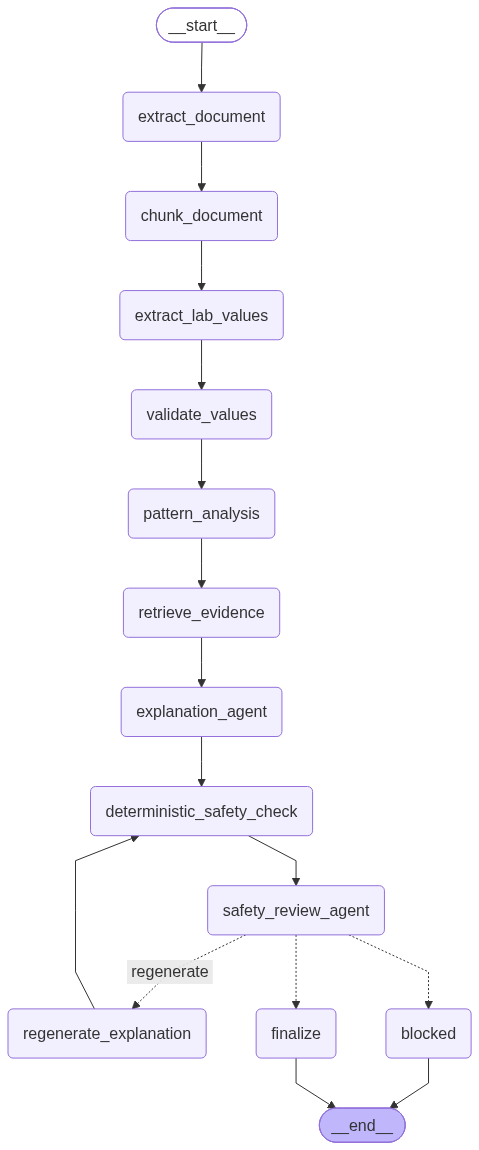

In [51]:
# ============================================================
# GRAPH VISUALIZATION
# ============================================================

try:

    from IPython.display import Image as IPImage, display

    graph_image = medical_graph.get_graph().draw_mermaid_png()

    display(
        IPImage(graph_image)
    )

except Exception as e:

    print(
        "Graph visualization unavailable:",
        e
    )

In [52]:
# ============================================================
# RUN COMPLETE MEDINSIGHT PIPELINE
# ============================================================

initial_state: MedicalReportState = {

    "report_path":
        REPORT_PATH,

    "safety_attempts":
        0,

    "errors":
        []
}


final_state = medical_graph.invoke(
    initial_state
)


print("\n")
print("=" * 80)
print("FINAL MEDINSIGHT REPORT")
print("=" * 80)

print(
    json.dumps(
        final_state["final_report"],
        indent=2,
        ensure_ascii=False
    )
)


NODE: DOCUMENT EXTRACTION
Extracted characters: 769

NODE: DOCUMENT CHUNKING
Created chunks: 1

NODE: STRUCTURED LAB EXTRACTION
Laboratory values extracted: 10

NODE: DETERMINISTIC VALIDATION
Validated results: 10
Validation errors: 0

NODE: PATTERN ANALYSIS AGENT
{
  "patterns": [
    {
      "name": "microcytic laboratory pattern",
      "description": "characterized by low mean corpuscular volume (MCV) and low mean corpuscular hemoglobin (MCH), indicating iron deficiency.",
      "supporting_tests": [
        "MCV",
        "MCH"
      ],
      "confidence": "high"
    },
    {
      "name": "iron-related laboratory pattern",
      "description": "evidenced by low hemoglobin, ferritin, and serum iron levels, consistent with iron deficiency.",
      "supporting_tests": [
        "Hemoglobin",
        "Ferritin",
        "Serum Iron"
      ],
      "confidence": "high"
    },
    {
      "name": "elevated WBC pattern",
      "description": "indicated by high white blood cell count, p

In [53]:
# ============================================================
# DISPLAY VALIDATED RESULTS
# ============================================================

final_results = final_state[
    "final_report"
].get(
    "laboratory_results",
    []
)

final_results_df = pd.DataFrame(
    final_results
)

final_results_df

,Test,Value,Unit,Reference Low,Reference High,Status
0,Hemoglobin,10.2,g/dL,12.0,15.5,LOW
1,WBC Count,12500.0,/uL,4000.0,11000.0,HIGH
2,Platelet Count,310000.0,/uL,150000.0,450000.0,NORMAL
3,MCV,74.0,fL,80.0,100.0,LOW
4,MCH,24.0,pg,27.0,33.0,LOW
5,Ferritin,9.0,ng/mL,15.0,150.0,LOW
6,Serum Iron,35.0,ug/dL,50.0,170.0,LOW
7,TIBC,420.0,ug/dL,250.0,450.0,NORMAL
8,Glucose (fasting),96.0,mg/dL,70.0,99.0,NORMAL
9,Creatinine,0.9,mg/dL,0.6,1.1,NORMAL


In [54]:
# ============================================================
# DISPLAY PATTERNS
# ============================================================

patterns = final_state[
    "final_report"
].get(
    "patterns",
    {}
)

print(
    json.dumps(
        patterns,
        indent=2,
        ensure_ascii=False
    )
)

{
  "patterns": [
    {
      "name": "microcytic laboratory pattern",
      "description": "characterized by low mean corpuscular volume (MCV) and low mean corpuscular hemoglobin (MCH), indicating iron deficiency.",
      "supporting_tests": [
        "MCV",
        "MCH"
      ],
      "confidence": "high"
    },
    {
      "name": "iron-related laboratory pattern",
      "description": "evidenced by low hemoglobin, ferritin, and serum iron levels, consistent with iron deficiency.",
      "supporting_tests": [
        "Hemoglobin",
        "Ferritin",
        "Serum Iron"
      ],
      "confidence": "high"
    },
    {
      "name": "elevated WBC pattern",
      "description": "indicated by high white blood cell count, possibly indicative of inflammation or infection.",
      "supporting_tests": [
        "WBC Count"
      ],
      "confidence": "moderate"
    }
  ]
}


In [55]:
# ============================================================
# DISPLAY RAG EVIDENCE
# ============================================================

evidence = final_state[
    "final_report"
].get(
    "retrieved_evidence",
    []
)

for i, item in enumerate(
    evidence,
    1
):

    print(
        f"\n--- Evidence {i} ---"
    )

    print(
        "Topic:",
        item["topic"]
    )

    print(
        "Score:",
        round(
            item["score"],
            4
        )
    )

    print(
        "Evidence:",
        item["evidence"]
    )


--- Evidence 1 ---
Topic: Iron-related laboratory pattern
Score: 0.7906
Evidence: A laboratory pattern involving low ferritin, low serum iron, relatively increased or high TIBC, and smaller red blood cell indices such as low MCV and low MCH can be associated with an iron-related laboratory pattern. Interpretation should consider the laboratory reference ranges and clinical context.

--- Evidence 2 ---
Topic: MCH
Score: 0.54
Evidence: Mean corpuscular hemoglobin (MCH) describes the average amount of hemoglobin contained in a red blood cell. A low MCH can occur with hypochromic red blood cells and should be interpreted together with other laboratory findings.

--- Evidence 3 ---
Topic: MCV
Score: 0.452
Evidence: Mean corpuscular volume (MCV) describes the average size of red blood cells. A low MCV indicates smaller-than-average red blood cells and is commonly described as a microcytic laboratory pattern.


In [57]:
# ============================================================
# DISPLAY EXPLANATION
# ============================================================

explanation = final_state[
    "final_report"
].get(
    "explanation",
    {}
)

print(
    json.dumps(
        explanation,
        indent=2,
        ensure_ascii=False
    )
)

{
  "summary": "The laboratory findings indicate a potential iron-related laboratory pattern characterized by low hemoglobin, ferritin, and serum iron levels, which may be consistent with iron deficiency. Additionally, there is a microcytic laboratory pattern indicated by low mean corpuscular volume (MCV) and mean corpuscular hemoglobin (MCH). The elevated white blood cell count suggests possible inflammation or infection, but this needs to be considered in the context of other findings. Overall, these findings should be interpreted cautiously and further evaluation may be necessary to confirm the diagnosis and guide appropriate management.",
  "key_findings": [
    {
      "finding": "Hemoglobin 10.2 g/dL (LOW)",
      "explanation": "This value is below the normal range and may be consistent with an iron-related laboratory pattern.",
      "supporting_tests": [
        "Hemoglobin"
      ]
    },
    {
      "finding": "MCV 74 fL (LOW)",
      "explanation": "This value is below the 

In [58]:
# ============================================================
# SAFETY RESULT
# ============================================================

safety = final_state[
    "final_report"
].get(
    "safety",
    {}
)

print(
    json.dumps(
        safety,
        indent=2,
        ensure_ascii=False
    )
)

{
  "deterministic": {
    "approved": true,
    "issues": []
  },
  "llm_review": {
    "approved": true,
    "issues": []
  }
}


In [59]:
# ============================================================
# EXPORT FINAL REPORT
# ============================================================

output_path = (
    OUTPUT_DIR /
    "medical_report_analysis.json"
)

with open(
    output_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        final_state["final_report"],
        f,
        indent=2,
        ensure_ascii=False
    )


print(
    "Saved:",
    output_path
)

print(
    "Size:",
    output_path.stat().st_size,
    "bytes"
)

Saved: /kaggle/working/medinsight_output/medical_report_analysis.json
Size: 6245 bytes


In [60]:
# ============================================================
# EXPORT LAB RESULTS
# ============================================================

csv_path = (
    OUTPUT_DIR /
    "validated_lab_results.csv"
)

final_results_df.to_csv(
    csv_path,
    index=False
)

print(
    "Saved:",
    csv_path
)

Saved: /kaggle/working/medinsight_output/validated_lab_results.csv


In [61]:
# ============================================================
# PROJECT SUMMARY
# ============================================================

print("""
============================================================
MEDINSIGHT AI
============================================================

Agentic Medical Report Analysis & RAG System

Pipeline:

1. Document Extraction
2. OCR fallback
3. Document Chunking
4. Structured Laboratory Extraction
5. Deterministic Validation
6. Pattern Analysis Agent
7. FAISS RAG Retrieval
8. Explanation Agent
9. Deterministic Safety Gate
10. LLM Safety Review
11. Conditional Regeneration
12. Safe Finalization / Blocking

Technologies:

Python
LangGraph
LangChain
Qwen2.5-3B-Instruct
Hugging Face Transformers
Sentence Transformers
FAISS
PyMuPDF
Tesseract OCR
Pydantic
Pandas
NumPy
PyTorch
CUDA

============================================================
""")


MEDINSIGHT AI

Agentic Medical Report Analysis & RAG System

Pipeline:

1. Document Extraction
2. OCR fallback
3. Document Chunking
4. Structured Laboratory Extraction
5. Deterministic Validation
6. Pattern Analysis Agent
7. FAISS RAG Retrieval
8. Explanation Agent
9. Deterministic Safety Gate
10. LLM Safety Review
11. Conditional Regeneration
12. Safe Finalization / Blocking

Technologies:

Python
LangGraph
LangChain
Qwen2.5-3B-Instruct
Hugging Face Transformers
Sentence Transformers
FAISS
PyMuPDF
Tesseract OCR
Pydantic
Pandas
NumPy
PyTorch
CUDA


